In [1]:
import pandas as pd
import numpy as np

In [2]:
data = pd.read_csv('../dataset.csv')

In [3]:
data.head()

,id,lhs,rhs,tablename,is_approx,null_eq_nul,is_genuine
0,0,DepTime,ArrDel15,croppedairline.csv,True,True,False
1,1,ArrTime,ArrDel15,croppedairline.csv,True,True,False
2,2,TailNum,ArrDel15,croppedairline.csv,True,True,False
3,3,ActualElapsedTime,ArrDel15,croppedairline.csv,True,True,False
4,4,AirTime,ArrDel15,croppedairline.csv,True,True,False


In [4]:
gen_ratio = np.float64( data["is_genuine"].sum(axis = 0)) / np.float64(data.count(axis=0).id) 

In [5]:
gen_ratio * 100

np.float64(32.92253521126761)

In [6]:
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity

sentenceTransformer = SentenceTransformer("all-MiniLM-L6-v2")


/home/jannis/University/dataprofiling/dataprofiling_gen_fd/datagen/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [7]:
texts = ["worker","supervisorID"]
embeddings = sentenceTransformer.encode(texts, normalize_embeddings=True)

sim = cosine_similarity(embeddings)

print(sim)

[[1.0000001 0.523237 ]
 [0.523237  1.0000002]]


In [8]:
def cos_string(lhs, rhs):
    texts = [lhs, rhs]
    embeddings = sentenceTransformer.encode(texts, normalize_embeddings=True)
    sim = cosine_similarity(embeddings)
    return str(sim[0][1])

In [9]:
def lcs_string(a: str, b: str) -> str:
    if not a or not b:
        return ""

    dp = [0] * (len(b) + 1)
    best_len = 0
    best_end = 0 

    for i in range(1, len(a) + 1):
        prev_diag = 0
        for j in range(1, len(b) + 1):
            tmp = dp[j]
            if a[i - 1] == b[j - 1]:
                dp[j] = prev_diag + 1
                if dp[j] > best_len:
                    best_len = dp[j]
                    best_end = i
            else:
                dp[j] = 0
            prev_diag = tmp
    nominator = float(min(len(a), len(b)))
    return float(len(a[best_end - best_len:best_end])) / nominator



In [10]:
import Levenshtein

def lev_string(lhs_, rhs):
    lhs = [x.strip() for x in lhs_.split(',')]
    min_distance = float('inf')
    for lhs_elem in lhs:
        distance = Levenshtein.distance(lhs_elem, rhs)
        if distance < min_distance:
            min_distance = distance
    nominator = max(len(lhs_), len(rhs))
    return 1.0 - (float(min_distance) / float(nominator))

In [12]:
examples = [
    ["worker","supervisorID"],
    ["postalcode","cityID"],
    ["WorkerKey","supervisorID"],
]

metrics = [
    lcs_string,
    lev_string,
    cos_string
]

for lhs,rhs in examples:
    for f in metrics:
        print(lhs + '->' + rhs + ': ' + str(f(lhs, rhs)))

worker->supervisorID: 0.3333333333333333
worker->supervisorID: 0.16666666666666663
worker->supervisorID: 0.523237
postalcode->cityID: 0.16666666666666666
postalcode->cityID: 0.09999999999999998
postalcode->cityID: 0.4412175
WorkerKey->supervisorID: 0.2222222222222222
WorkerKey->supervisorID: 0.08333333333333337
WorkerKey->supervisorID: 0.44150972


In [13]:
def build_cosine_sim(row):
    lhs = row['lhs']
    rhs = row['rhs']
    texts = [lhs, rhs]
    embeddings = sentenceTransformer.encode(texts, normalize_embeddings=True)
    sim = cosine_similarity(embeddings)
    return sim[0][1]

In [14]:
def build_levenshtein(row):
    lhs = [x.strip() for x in row['lhs'].split(',')]
    rhs = row['rhs']
    min_distance = float('inf')
    min_lhs = '0'
    for lhs_elem in lhs:
        distance = Levenshtein.distance(lhs_elem, rhs)
        if distance < min_distance:
            min_distance = distance
            min_lhs = lhs_elem
    nominator = max(len(min_lhs), len(rhs))
    return 1.0 - (float(min_distance) / float(nominator))

In [15]:
def build_lcs(row):
    lhs = [x.strip() for x in row['lhs'].split(',')]
    rhs = row['rhs']
    max_distance = 0
    for lhs_elem in lhs:
        distance = lcs_string(lhs_elem, rhs)
        if distance >= max_distance:
            max_distance = distance
    return distance

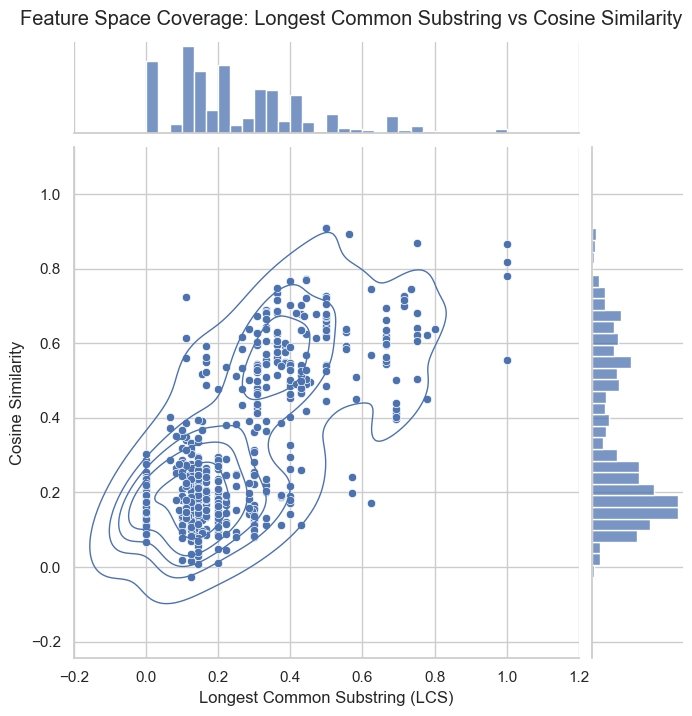

In [16]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1) Compute features (same pattern as your code)
lcs = data.apply(build_lcs, axis=1)
cos = data.apply(build_cosine_sim, axis=1)

# 2) Clean + assemble
df_plot = pd.DataFrame({
    "Longest Common Substring (LCS)": pd.to_numeric(lcs, errors="coerce"),
    "Cosine Similarity": pd.to_numeric(cos, errors="coerce"),
}).dropna()

# Optional: if LCS is a length-like feature with a wide integer range,
# you can keep it as-is for "broad range" messaging.
# If you want comparability, normalize it yourself before plotting.

sns.set_theme(style="whitegrid")

# 3) Joint plot: scatter + marginals
g = sns.jointplot(
    data=df_plot,
    x="Longest Common Substring (LCS)",
    y="Cosine Similarity",
    kind="scatter",
    height=7,
    space=0.15,
    marginal_kws=dict(bins=30, fill=True),
)

# 4) Add density contour on top of scatter (helps highlight structure)
sns.kdeplot(
    data=df_plot,
    x="Longest Common Substring (LCS)",
    y="Cosine Similarity",
    ax=g.ax_joint,
    levels=6,
    linewidths=1,
)

# 5) Titles/labels to make the narrative explicit
g.fig.suptitle(
    "Feature Space Coverage: Longest Common Substring vs Cosine Similarity",
    y=1.02
)
g.ax_joint.set_xlabel("Longest Common Substring (LCS)")
g.ax_joint.set_ylabel("Cosine Similarity")

plt.show()


In [17]:
lcs = data.apply(build_lcs, axis=1)

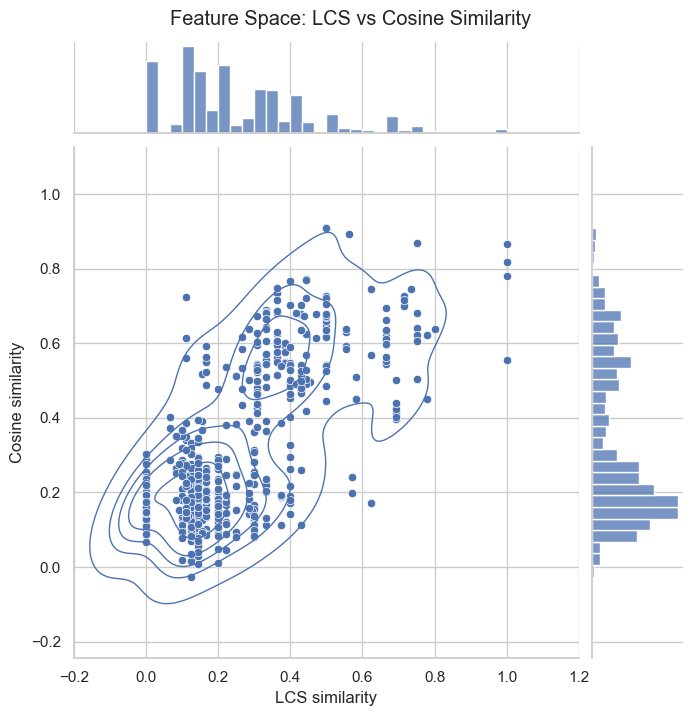

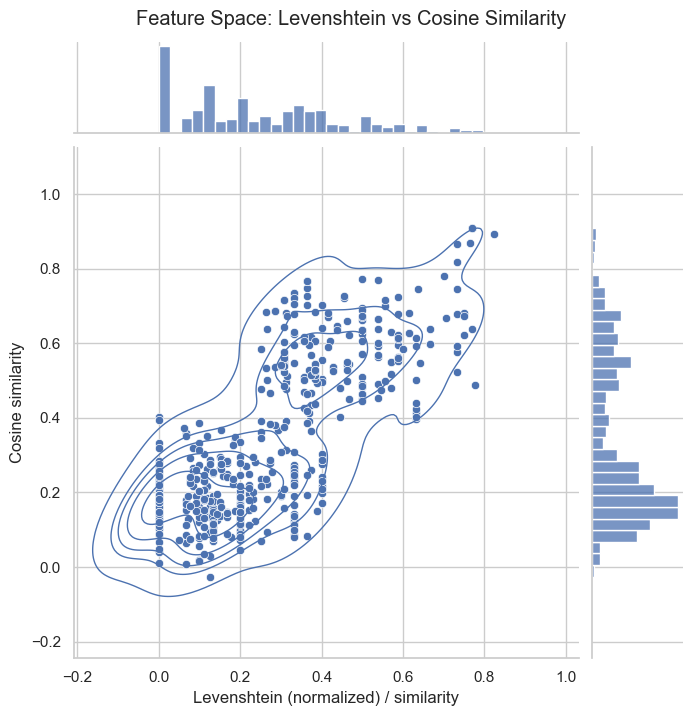

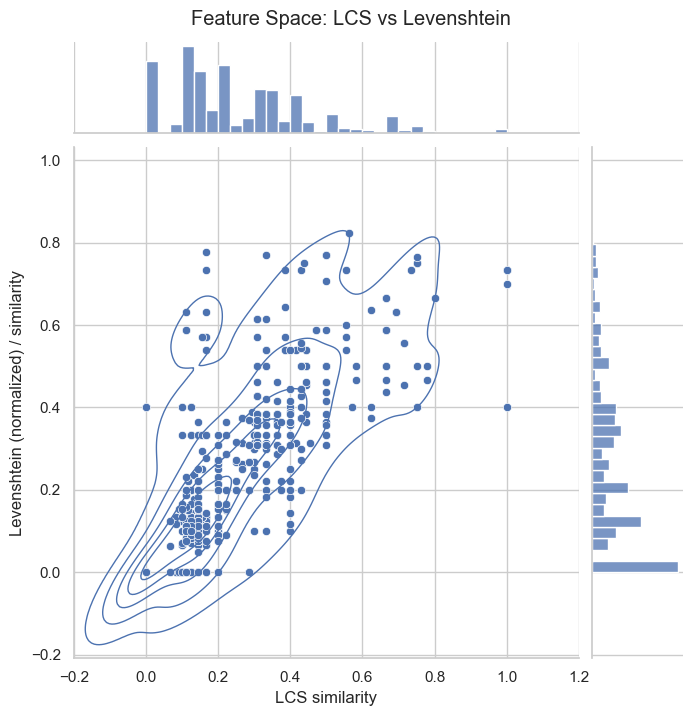

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

def make_jointplot(data, x_series, y_series, x_label, y_label, title,
                   bins=30, height=7, kde_levels=6):
    """Seaborn joint plot: scatter + marginal histograms + KDE contour overlay."""
    df_plot = pd.DataFrame({
        x_label: pd.to_numeric(x_series, errors="coerce"),
        y_label: pd.to_numeric(y_series, errors="coerce"),
    }).dropna()

    g = sns.jointplot(
        data=df_plot,
        x=x_label,
        y=y_label,
        kind="scatter",
        height=height,
        space=0.15,
        marginal_kws=dict(bins=bins, fill=True),
    )

    # density contours on top of the scatter
    sns.kdeplot(
        data=df_plot,
        x=x_label,
        y=y_label,
        ax=g.ax_joint,
        levels=kde_levels,
        linewidths=1,
    )

    g.fig.suptitle(title, y=1.02)
    g.ax_joint.set_xlabel(x_label)
    g.ax_joint.set_ylabel(y_label)

    plt.show()
    return g

# --- Compute features once (avoid recomputing 3x) ---
lcs = data.apply(build_lcs, axis=1)
cos = data.apply(build_cosine_sim, axis=1)
lev = data.apply(build_levenshtein, axis=1)

# --- 1) build_lcs vs build_cosine_sim ---
make_jointplot(
    data=data,
    x_series=lcs,
    y_series=cos,
    x_label="LCS similarity",
    y_label="Cosine similarity",
    title="Feature Space: LCS vs Cosine Similarity",
)

# --- 2) build_lev vs build_cosine_sim ---
make_jointplot(
    data=data,
    x_series=lev,
    y_series=cos,
    x_label="Levenshtein (normalized) / similarity",
    y_label="Cosine similarity",
    title="Feature Space: Levenshtein vs Cosine Similarity",
)

# --- 3) build_lcs vs build_lev ---
make_jointplot(
    data=data,
    x_series=lcs,
    y_series=lev,
    x_label="LCS similarity",
    y_label="Levenshtein (normalized) / similarity",
    title="Feature Space: LCS vs Levenshtein",
)


In [19]:
data[(lcs - cos).abs() == (lcs - cos).abs().max()]

,id,lhs,rhs,tablename,is_approx,null_eq_nul,is_genuine
169,152,"country_code, airport_name, city_name",airport_iata_code,mondialjoin.csv,False,True,True


In [20]:
(lcs - cos).abs().sort_values(ascending=False)

169    0.612989
195    0.501553
163    0.452817
209    0.448215
156    0.445146
         ...   
161    0.001571
83     0.001491
184    0.000503
242    0.000277
15     0.000222
Length: 568, dtype: float64

In [21]:
getValue = (lcs - cos).abs().sort_values(ascending=False)[1]

In [22]:
data[(lcs - cos).abs() == getValue]

,id,lhs,rhs,tablename,is_approx,null_eq_nul,is_genuine
1,1,ArrTime,ArrDel15,croppedairline.csv,True,True,False


In [23]:
examples = [
    ["worker","supervisorID"],
    ["postalcode","cityID"],
    ["DepDelay","DepartureDelayGroups"],
    ["birthdate","deathdate"],
    ["movieID","title"],
]

metrics = [
    ['lcs', lcs_string],
    ['lev',lev_string],
    ['cos', cos_string]
]

for lhs,rhs in examples:
    for t, f in metrics:
        print(lhs + '->' + rhs +' '+ t +' : ' + str(f(lhs, rhs)))

worker->supervisorID lcs : 0.3333333333333333
worker->supervisorID lev : 0.16666666666666663
worker->supervisorID cos : 0.523237
postalcode->cityID lcs : 0.16666666666666666
postalcode->cityID lev : 0.09999999999999998
postalcode->cityID cos : 0.4412175
DepDelay->DepartureDelayGroups lcs : 0.625
DepDelay->DepartureDelayGroups lev : 0.4
DepDelay->DepartureDelayGroups cos : 0.17218277
birthdate->deathdate lcs : 0.6666666666666666
birthdate->deathdate lev : 0.6666666666666667
birthdate->deathdate cos : 0.5987719
movieID->title lcs : 0.2
movieID->title lev : 0.1428571428571429
movieID->title cos : 0.280063


In [24]:
data.iloc[(lcs - cos).abs().sort_values(ascending=False).index]

,id,lhs,rhs,tablename,is_approx,null_eq_nul,is_genuine
169,152,"country_code, airport_name, city_name",airport_iata_code,mondialjoin.csv,False,True,True
195,178,"language_name, country_population",language_percentage,mondialjoin.csv,False,True,False
163,14,DepDelay,DepartureDelayGroups,croppedairline.csv,True,True,True
209,192,"airport_name, language_percentage, city_name",airport_iata_code,mondialjoin.csv,False,True,False
156,7,Origin,OriginStateName,croppedairline.csv,True,True,True
...,...,...,...,...,...,...,...
161,12,OriginCityMarketID,OriginStateName,croppedairline.csv,True,True,True
83,83,"Dest, ArrDelay",OriginStateName,croppedairline.csv,True,True,False
184,167,airport_latitude,country_population,mondialjoin.csv,False,True,False
242,225,EmployeeID,emp_ReportsTo,northwind.csv,False,True,True


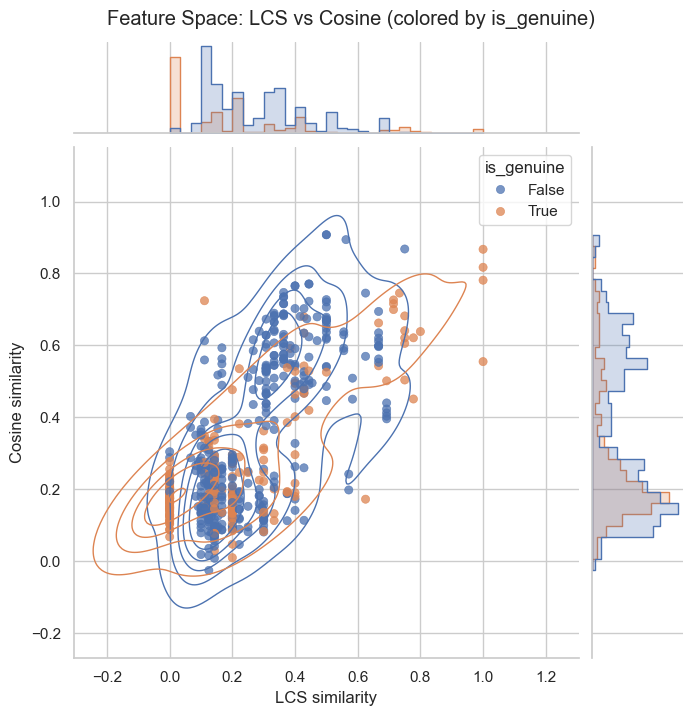

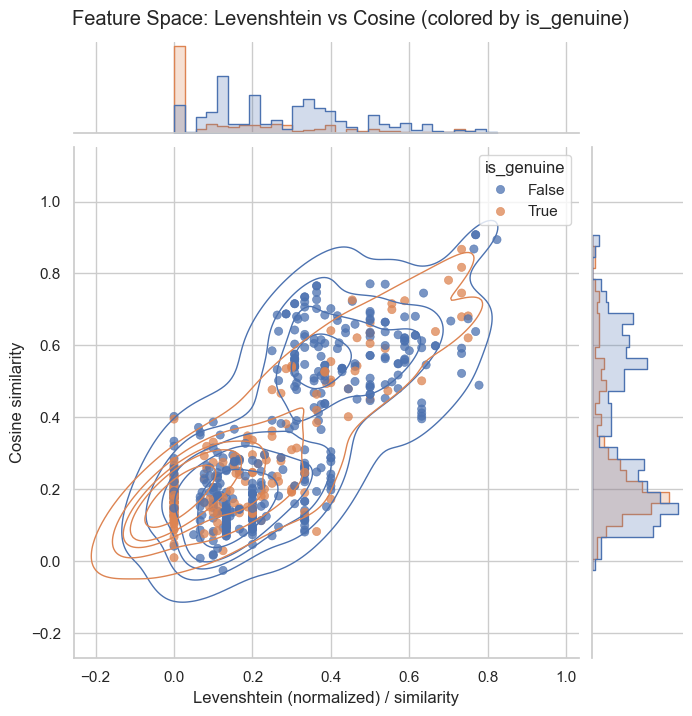

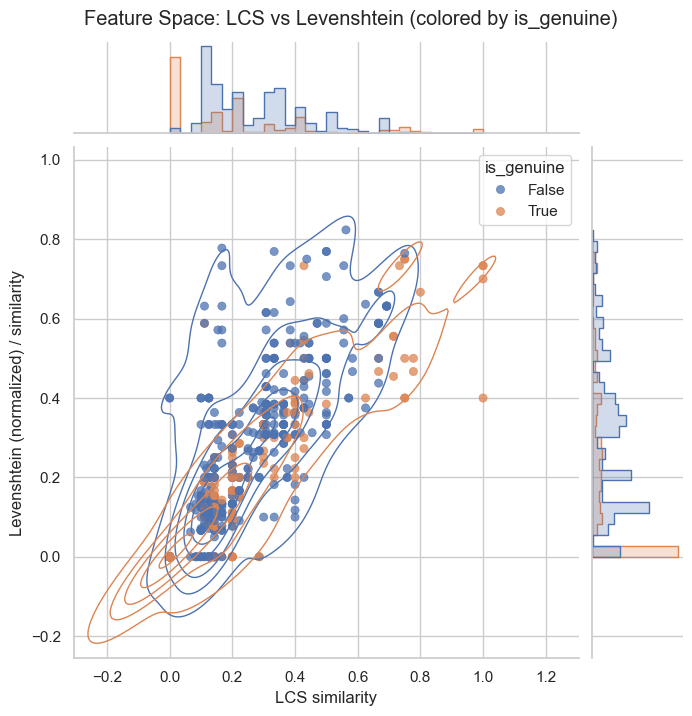

In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

def make_jointplot_classified(data, x_series, y_series, x_label, y_label, title,
                              label_col="is_genuine", bins=30, height=7, kde_levels=6):
    df_plot = pd.DataFrame({
        x_label: pd.to_numeric(x_series, errors="coerce"),
        y_label: pd.to_numeric(y_series, errors="coerce"),
        label_col: data[label_col].astype(bool).values,  # align to data order
    }).dropna()

    # Base joint grid (empty-ish), then we add our own plots for full control
    g = sns.JointGrid(
        data=df_plot,
        x=x_label,
        y=y_label,
        height=height,
        space=0.15,
    )

    # Scatter colored by class
    sns.scatterplot(
        data=df_plot,
        x=x_label,
        y=y_label,
        hue=label_col,
        alpha=0.75,
        s=35,
        ax=g.ax_joint,
        edgecolor=None,
    )

    # Marginal histograms split by class
    sns.histplot(
        data=df_plot,
        x=x_label,
        hue=label_col,
        bins=bins,
        element="step",
        stat="count",
        common_norm=False,
        ax=g.ax_marg_x,
        legend=False,
    )
    sns.histplot(
        data=df_plot,
        y=y_label,
        hue=label_col,
        bins=bins,
        element="step",
        stat="count",
        common_norm=False,
        ax=g.ax_marg_y,
        legend=False,
    )

    # KDE contours over the full point cloud (optionally: do per-class instead)
    sns.kdeplot(
        data=df_plot,
        x=x_label,
        y=y_label,
        hue=label_col,
        levels=kde_levels,
        linewidths=1,
        ax=g.ax_joint,
        legend=False,
    )


    g.fig.suptitle(title, y=1.02)
    g.ax_joint.set_xlabel(x_label)
    g.ax_joint.set_ylabel(y_label)

    # Legend formatting
    g.ax_joint.legend(title=label_col, loc="best", frameon=True)

    plt.show()
    return g

# --- Compute features once ---
lcs = data.apply(build_lcs, axis=1)
cos = data.apply(build_cosine_sim, axis=1)
lev = data.apply(build_levenshtein, axis=1)

# --- 1) LCS vs Cosine ---
make_jointplot_classified(
    data=data,
    x_series=lcs,
    y_series=cos,
    x_label="LCS similarity",
    y_label="Cosine similarity",
    title="Feature Space: LCS vs Cosine (colored by is_genuine)",
)

# --- 2) Levenshtein vs Cosine ---
make_jointplot_classified(
    data=data,
    x_series=lev,
    y_series=cos,
    x_label="Levenshtein (normalized) / similarity",
    y_label="Cosine similarity",
    title="Feature Space: Levenshtein vs Cosine (colored by is_genuine)",
)

# --- 3) LCS vs Levenshtein ---
make_jointplot_classified(
    data=data,
    x_series=lcs,
    y_series=lev,
    x_label="LCS similarity",
    y_label="Levenshtein (normalized) / similarity",
    title="Feature Space: LCS vs Levenshtein (colored by is_genuine)",
)


In [26]:
# seperator signs upperCase, hyphen, underscore
# has id, key, name, identifier
from itertools import product
import re

# global list for key indicators
keyAlike = ['id', 'key', 'name', 'identifier']
def upper_case_key(entry):
    lhs = entry['lhs']
    def split_by_uppercase(s: str) -> list[str]:
        s = s.strip()
        if not s:
            return []
        parts = re.split(r"(?<=[a-z0-9])(?=[A-Z])|(?<=[A-Z])(?=[A-Z][a-z])", s)
        return [p for p in parts if p]
    attributes = [a.strip() for a in lhs.split(',') if a.strip()]
    split_has_key = False
    for attribute in attributes:
        up_split = split_by_uppercase( attribute )
        split_has_key = split_has_key or any(p[0].lower() == p[1].lower() for p in product(up_split, keyAlike))
    return split_has_key

def hyphen_key(entry):
    lhs = entry['lhs']
    attributes = [a.strip() for a in lhs.split(',') if a.strip()]
    
    def split_by_hyphen(s: str) -> list[str]:
        s = s.strip()
        if not s:
            return []
        return [p for p in s.split("-") if p]
    
    split_has_hyphen = False
    for attribute in attributes:
        hy_split = split_by_hyphen( attribute )
        split_has_hyphen = split_has_hyphen or any(p[0].lower() == p[1].lower() for p in product(hy_split, keyAlike))
    return split_has_hyphen

def underscore_key(entry):
    lhs = entry['lhs']
    attributes = [a.strip() for a in lhs.split(',') if a.strip()]
    
    def split_by_underscore(s: str) -> list[str]:
        s = s.strip()
        if not s:
            return []
        return [p for p in s.split("_") if p]
    
    split_has_underscore = False
    for attribute in attributes:
        un_split = split_by_underscore( attribute )
        split_has_underscore = split_has_underscore or any(p[0].lower() == p[1].lower() for p in product(un_split, keyAlike))
    return split_has_underscore

def contains_key(entry):
    lhs = entry['lhs']
    attributes = [a.strip() for a in lhs.split(',') if a.strip()]
    
    contains_any = any( key.lower() in attribute.lower() for attribute,key in product(attributes, keyAlike) )
    return contains_any


In [27]:
feature_fns = {
    "upper_case_key": upper_case_key,
    "hyphen_key": hyphen_key,
    "underscore_key": underscore_key,
    "contains_key": contains_key,
}

df_feat = data.copy()

for name, fn in feature_fns.items():
    df_feat[name] = df_feat.apply(fn, axis=1).astype(int)

df_feat["is_genuine"] = df_feat["is_genuine"].astype(int)


In [28]:
import pandas as pd

df_long = df_feat.melt(
    id_vars="is_genuine",
    value_vars=list(feature_fns.keys()),
    var_name="feature",
    value_name="feature_present",
)


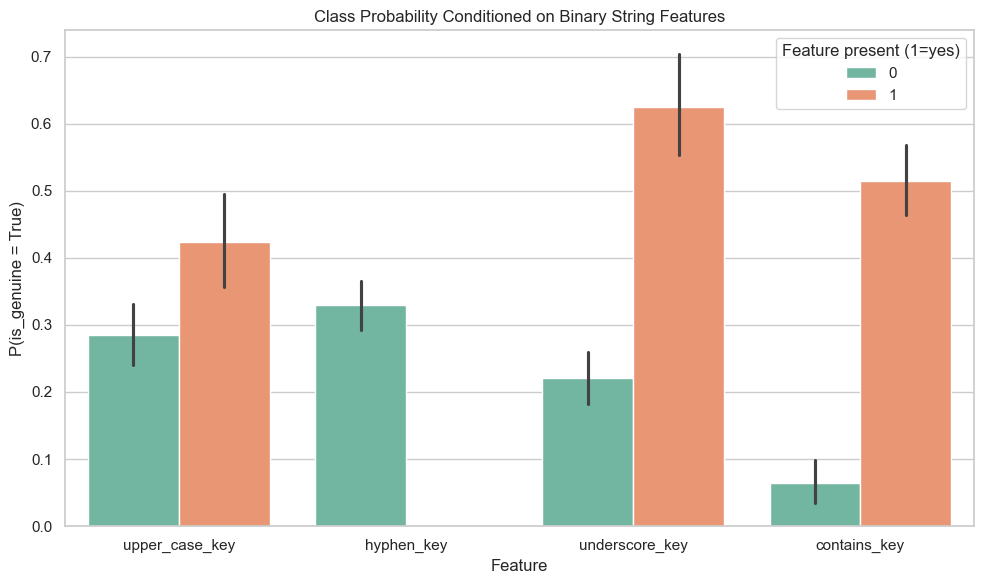

In [29]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 6))

sns.barplot(
    data=df_long,
    x="feature",
    y="is_genuine",
    hue="feature_present",
    estimator="mean",        # mean of is_genuine = P(genuine)
    errorbar=("ci", 95),
    palette="Set2",
)

plt.ylabel("P(is_genuine = True)")
plt.xlabel("Feature")
plt.title("Class Probability Conditioned on Binary String Features")
plt.legend(title="Feature present (1=yes)")

plt.tight_layout()
plt.show()


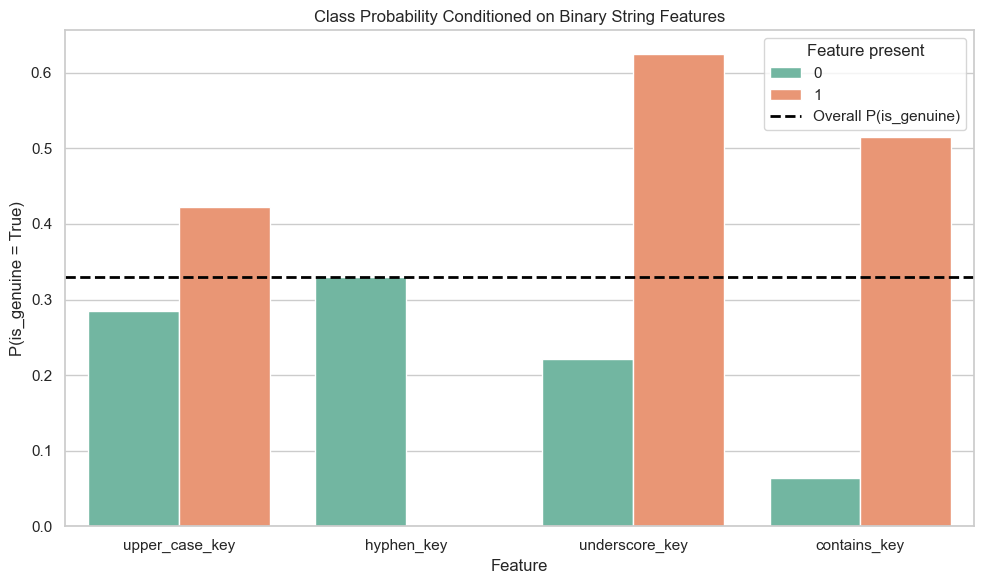

In [30]:
plt.figure(figsize=(10, 6))
base_rate = data["is_genuine"].mean()


sns.barplot(
    data=df_long,
    x="feature",
    y="is_genuine",
    hue="feature_present",
    estimator="mean",
    errorbar=None,
    palette="Set2",
)

plt.axhline(
    base_rate,
    color="black",
    linestyle="--",
    linewidth=2,
    label="Overall P(is_genuine)"
)

plt.ylabel("P(is_genuine = True)")
plt.xlabel("Feature")
plt.title("Class Probability Conditioned on Binary String Features")
plt.legend(title="Feature present")

plt.tight_layout()
plt.show()


In [31]:
# todo function: databasename + attributename -> SQL Type
#basketball team: "bioID","firstName","middleName","lastName","nameGiven","fullGivenName","marriedName","nameNick","pos","firstseason","lastseason","height","weight","college","collegeOther","birthDate","birthCity","birthState","birthCountry","highSchool","hsCity","hsState","hsCountry","deathDate","year","stint","tmID","lgID","GP","GS","minutes","points","oRebounds","dRebounds","rebounds","assists","steals","blocks","turnovers","PF","fgAttempted","fgMade","ftAttempted","ftMade","threeAttempted","threeMade","dq","PostGP","PostGS","PostMinutes","PostPoints","PostoRebounds","PostdRebounds","PostRebounds","PostAssists","PostSteals","PostBlocks","PostTurnovers","PostPF","PostfgAttempted","PostfgMade","PostftAttempted","PostftMade","PostthreeAttempted","PostthreeMade","PostDQ"
basektball_datatypes = {'bioID': 'varchar', 'firstName': 'varchar', 'middleName': 'varchar', 'lastName': 'varchar', 'nameGiven': 'varchar', 'fullGivenName': 'varchar', 'marriedName': 'varchar', 'nameNick': 'varchar', 'pos': 'varchar', 'firstseason':'int', 'lastseason':'int', 'height': 'float', 'weight':'int', 'college':'varchar', 'collegeOther':'varchar', 'birthDate':'date', 'birthCity':'varchar', 'birthState':'varchar', 'birthCountry':'varchar', 'highSchool':'varchar', 'hsCity':'varchar', 'hsState':'varchar', 'hsCountry':'varchar', 'deathDate':'date', 'year':'int', 'stint':'int', 'tmID':'varchar', 'lgID':'varchar', 'GP':'int', 'GS':'int', 'minutes':'int', 'points':'int', 'oRebounds':'int', 'dRebounds':'int', 'rebounds':'int', 'assists':'int', 'steals':'int', 'blocks':'int', 'turnovers':'int', 'PF':'int', 'fgAttempted':'int', 'fgMade':'int', 'ftAttempted':'int', 'ftMade':'int', 'threeAttempted':'int', 'threeMade':'int', 'dq':'int', 'PostGP':'int', 'PostGS':'int', 'PostMinutes':'int', 'PostPoints':'int', 'PostoRebounds':'int', 'PostdRebounds':'int', 'PostRebounds':'int', 'PostAssists':'int', 'PostSteals':'int', 'PostBlocks':'int', 'PostTurnovers':'int', 'PostPF':'int', 'PostfgAttempted':'int', 'PostfgMade':'int', 'PostftAttempted':'int', 'PostftMade':'int', 'PostthreeAttempted':'int', 'PostthreeMade':'int', 'PostDQ':'int'}
airline_datatypes ={ 'Year': 'int', 'Quarter':'int', 'Month':'int', 'DayofMonth':'int', 'DayOfWeek':'int', 'FlightDate':'date', 'UniqueCarrier':'varchar', 'AirlineID':'int', 'Carrier':'char', 'TailNum':'varchar', 'FlightNum':'int', 'OriginAirportID':'int', 'OriginAirportSeqID':'int', 'OriginCityMarketID':'int', 'Origin': 'char', 'OriginCityName': 'varchar', 'OriginState': 'char', 'OriginStateFips': 'int', 'OriginStateName': 'varchar', 'OriginWac': 'int', 'DestAirportID': 'int', 'DestAirportSeqID':'int', 'DestCityMarketID':'int', 'Dest':'char', 'DestCityName':'varchar', 'DestState':'char', 'DestStateFips':'int', 'DestStateName':'varchar', 'DestWac':'int', 'CRSDepTime':'int', 'DepTime':'int', 'DepDelay':'decimal', 'DepDelayMinutes':'float', 'DepDel15':'int', 'DepartureDelayGroups':'int', 'DepTimeBlk':'char', 'TaxiOut':'float', 'TaxiIn':'float', 'CRSArrTime':'int', 'ArrTime':'int', 'ArrDelay': 'decimal', 'ArrDelayMinutes': 'float', 'ArrDel15': 'int', 'ArrivalDelayGroups': 'ArrivalDelayGroups', 'ArrTimeBlk': 'char', 'Cancelled': 'int', 'CancellationCode': 'char', 'Diverted': 'int', 'CRSElapsedTime': 'float',  'ActualElapsedTime': 'float', 'AirTime': 'float', 'Flights': 'float', 'Distance':'float', 'DistanceGroup':'int', 'CarrierDelay': 'decimal', 'WeatherDelay':'decimal', 'NASDelay':'decimal', 'SecurityDelay':'decimal', 'LateAircraftDelay':'decimal', 'FirstDepTime':'decimal', 'TotalAddGTime':'decimal', 'LongestAddGTime':'decimal'}
mondial_datatypes = {"country_code": 'varchar',  "country_name":'varchar',  "country_capital_name":'varchar',  "country_capital_province":'varchar',  "country_area":'int',  "country_population":'int',  "city_position":'varchar',  "city_name":'varchar',  "city_country_code":'varchar',  "city_province":'varchar',  "city_population":'int',  "city_latitude":'double',  "city_longitude":'double',  "city_elevation":'int',  "airport_iata_code":'varchar',  "airport_name":'varchar',  "airport_country_code":'varchar',  "airport_city_name":'varchar',  "airport_province":'varchar',  "airport_island":'varchar',  "airport_latitude":'float',  "airport_longitude":'float',  "airport_elevation":'int',  "airport_gmt_offset":'int',  "language_name":'varchar',  "language_percentage":'double'  }
northwind_datatypes = {"OrderID":'int', "CustomerID":'varchar', "EmployeeID":'int', "ProductID":'int', "ord_OrderDate":'timestamp', "ord_RequiredDate":'timestamp', "ord_ShippedDate":'timestamp', "ord_ShipVia":'int', "ord_Freight":'double', "ord_ShipName":'varchar', "ord_ShipAddress":'varchar', "ord_ShipCity":'varchar', "ord_ShipRegion":'varchar', "ord_ShipPostalCode":'varchar', "ord_ShipCountry":'varchar', "cust_CompanyName":'varchar', "cust_ContactName":'varchar', "cust_ContactTitle":'varchar', "cust_Address":'varchar', "cust_City":'varchar', "cust_Region":'varchar', "cust_PostalCode":'varchar', "cust_Country":'varchar', "cust_Phone":'varchar', "cust_Fax":'varchar', "emp_LastName":'varchar', "emp_FirstName":'varchar', "emp_Title":'varchar', "emp_TitleOfCourtesy":'varchar', "emp_BirthDate":'timestamp', "emp_HireDate":'timestamp', "emp_Address":'varchar', "emp_City":'varchar', "emp_Region":'varchar', "emp_PostalCode":'varchar', "emp_Country":'varchar', "emp_HomePhone":'varchar', "emp_Extension":'int', "emp_ReportsTo":'int', "od_UnitPrice":'double', "od_Quantity": 'int', "od_Discount":'double', "prd_ProductName":'varchar', "prd_SupplierID":'int', "prd_CategoryID":'int', "prd_QuantityPerUnit":'varchar', "prd_UnitPrice":'double', "prd_UnitsInStock":'int', "prd_UnitsOnOrder":'int', "prd_ReorderLevel":'int', "prd_Discontinued":'bool',}
financial_datatypes = {"account_id": 'int', "account_date": 'date', "disp_id":'int', "disp_type":'varchar', "client_id":'int', "gender": 'varchar', "birth_date":'date', "district_id":'int', "A2":'varchar', "A3":'varchar', "A4":'int', "A5":'int', "A6":'int', "A7":'int', "A8":'int', "A9":'int', "A10":'decimal', "A11":'int', "A12":'decimal', "A13":'decimal', "A14":'int', "A15":'int', "A16":'int', "loan_id":'int', "loan_date":'date', "loan_amount":'int', "duration":'int', "payments":'decimal', "status": 'varchar', "order_id":'int', "bank_to":'varchar', "account_to":'int', "order_amount":'decimal', "k_symbol":'varchar'}

In [32]:
def datatype_for_row(lhs, rhs, dataset_name):
    datatypes = {}
    if dataset_name == 'croppedairline.csv':
        datatypes = airline_datatypes
    elif dataset_name == 'women_basketball.csv':
        datatypes = basektball_datatypes
    elif dataset_name == 'mondialjoin.csv':
        datatypes = mondial_datatypes
    elif dataset_name == 'northwind.csv':
        datatypes = northwind_datatypes
    elif dataset_name == 'financial.csv':
        datatypes = financial_datatypes
    else:
        return 'unknown', 'unknown'
    
    lhs_types = []
    for attr in lhs.split(','):
        attr = attr.strip()
        if attr in datatypes:
            lhs_types.append(datatypes[attr])
        else:
            lhs_types.append('unknown')
    
    rhs_type = datatypes.get(rhs, 'unknown')
    
    return ','.join(lhs_types), rhs_type

In [33]:
data_ft = data.copy() 
data_ft[['lhs_datatypes', 'rhs_datatype']] = data.apply(lambda row: datatype_for_row(row['lhs'], row['rhs'], row['tablename']), axis=1, result_type="expand")

In [34]:
result = data_ft.groupby(['lhs_datatypes', 'rhs_datatype','is_genuine']).size().unstack(fill_value=0)

In [35]:
result.sort_values(by=False,axis=0, ascending=False)

,is_genuine,False,True
lhs_datatypes,rhs_datatype,,
varchar,varchar,86,31
int,int,41,66
varchar,int,35,4
float,int,20,2
int,varchar,15,43
...,...,...,...
"double,double",varchar,0,1
int,timestamp,0,4
varchar,float,0,1


In [36]:
ratios = result.apply(lambda x: -1 if x[False] == 0 else x[True] / x[False], axis=1)
ratios[ratios >= 0].sort_values(ascending=True)[60:]

lhs_datatypes           rhs_datatype
varchar,double,varchar  varchar         0.000000
varchar,double          varchar         0.000000
varchar,decimal         varchar         0.000000
varchar,date            varchar         0.000000
float                   int             0.100000
varchar                 int             0.114286
int                     char            0.333333
varchar                 varchar         0.360465
int                     date            1.400000
                        int             1.609756
varchar                 date            2.000000
int                     varchar         2.866667
decimal                 int             3.000000
int                     decimal         3.500000
dtype: float64

In [37]:
def get_entry(result, lhs, rhs):
    return result.loc[(lhs, rhs)]

In [38]:
get_entry(result, 'int', 'date')

is_genuine
False    5
True     7
Name: (int, date), dtype: int64

In [39]:
from scipy.stats import entropy

In [47]:
1 - (entropy([0.01,0.99]) / entropy([0.5,0.5]))

np.float64(0.9192068641040888)

In [82]:
from scipy.special import logsumexp
def lower_bound(max_matches, p_rhs):
    return np.exp(logsumexp( max_matches * np.log(p_rhs)))

In [83]:
p_rhs_boring = [1.0]
p_rhs_lessboring = [0.999, 0.001]
p_rhs_realistic = [0.8, 0.2]
p_rhs_even = [0.5, 0.5]
matches_big = 1000
matches_medium = 100
matches_small = 10

In [84]:
print(f'p_rhs_boring with {matches_big} has {lower_bound(matches_big, p_rhs_boring)}')
print(f'p_rhs_boring with {matches_medium} has {lower_bound(matches_big, p_rhs_boring)}')
print(f'p_rhs_boring with {matches_small} has {lower_bound(matches_big, p_rhs_boring)}')
print(f'p_rhs_lessboring with {matches_big} has {lower_bound(matches_big, p_rhs_lessboring)}')
print(f'p_rhs_lessboring with {matches_medium} has {lower_bound(matches_medium, p_rhs_lessboring)}')
print(f'p_rhs_lessboring with {matches_small} has {lower_bound(matches_small, p_rhs_lessboring)}')
print(f'p_rhs_realistic with {matches_big} has {lower_bound(matches_big, p_rhs_realistic)}')
print(f'p_rhs_realistic with {matches_medium} has {lower_bound(matches_medium, p_rhs_realistic)}')
print(f'p_rhs_realistic with {matches_small} has {lower_bound(matches_small, p_rhs_realistic)}')
print(f'p_rhs_even with {matches_big} has {lower_bound(matches_big, p_rhs_even)}')
print(f'p_rhs_even with {matches_medium} has {lower_bound(matches_medium, p_rhs_even)}')
print(f'p_rhs_even with {matches_small} has {lower_bound(matches_small, p_rhs_even)}')

p_rhs_boring with 1000 has 1.0
p_rhs_boring with 100 has 1.0
p_rhs_boring with 10 has 1.0
p_rhs_lessboring with 1000 has 0.36769542477096373
p_rhs_lessboring with 100 has 0.9047921471137089
p_rhs_lessboring with 10 has 0.9900448802097482
p_rhs_realistic with 1000 has 1.230231922161183e-97
p_rhs_realistic with 100 has 2.0370359763344954e-10
p_rhs_realistic with 10 has 0.10737428480000005
p_rhs_even with 1000 has 1.866527237006463e-301
p_rhs_even with 100 has 1.577721810442024e-30
p_rhs_even with 10 has 0.001953125


In [ ]:
# evenly vs lower bound for fixed n


In [ ]:
# uneven for running m

/tmp/ipykernel_48188/2004354049.py:7: RuntimeWarning: divide by zero encountered in log
  return float(np.exp(logsumexp(max_matches * np.log(p_rhs))))


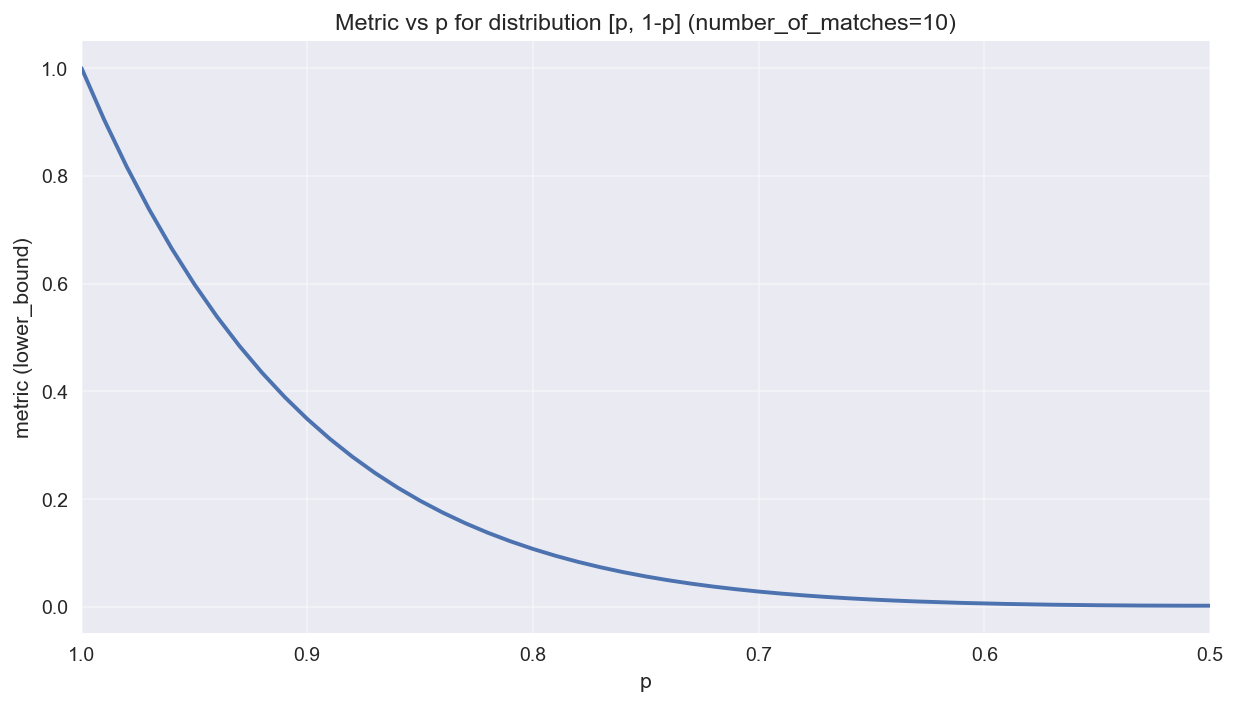

/tmp/ipykernel_48188/2004354049.py:7: RuntimeWarning: divide by zero encountered in log
  return float(np.exp(logsumexp(max_matches * np.log(p_rhs))))


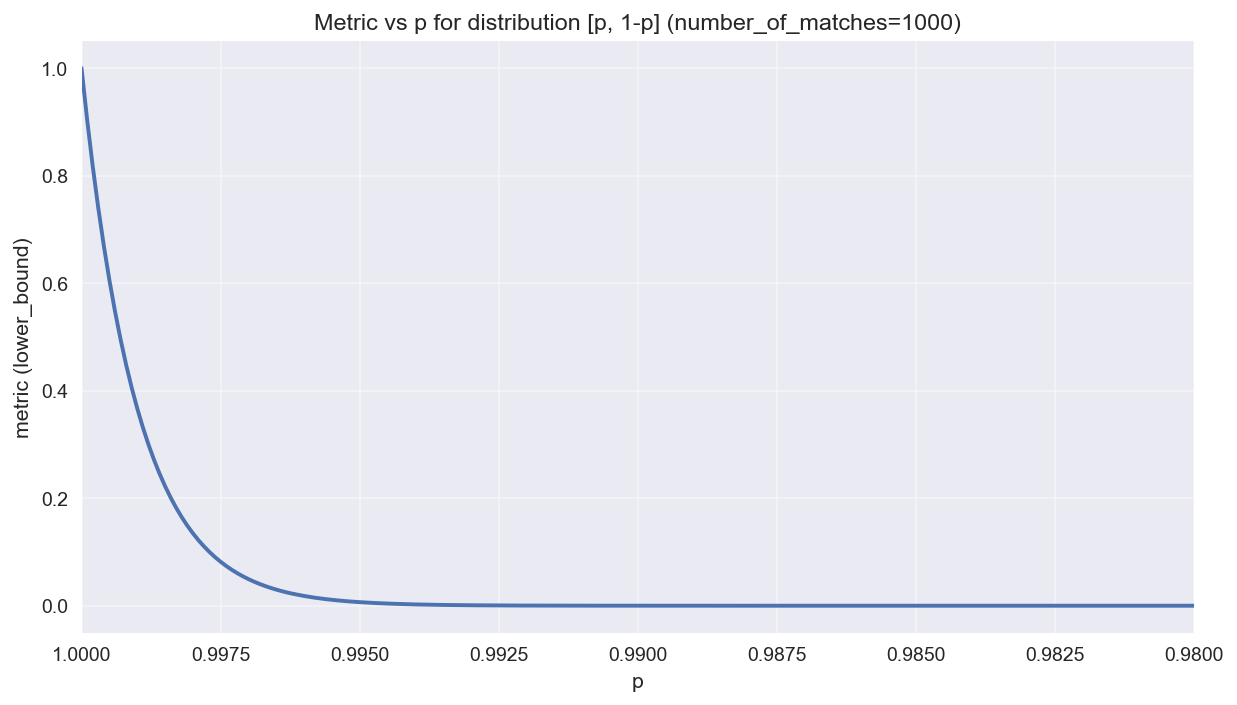

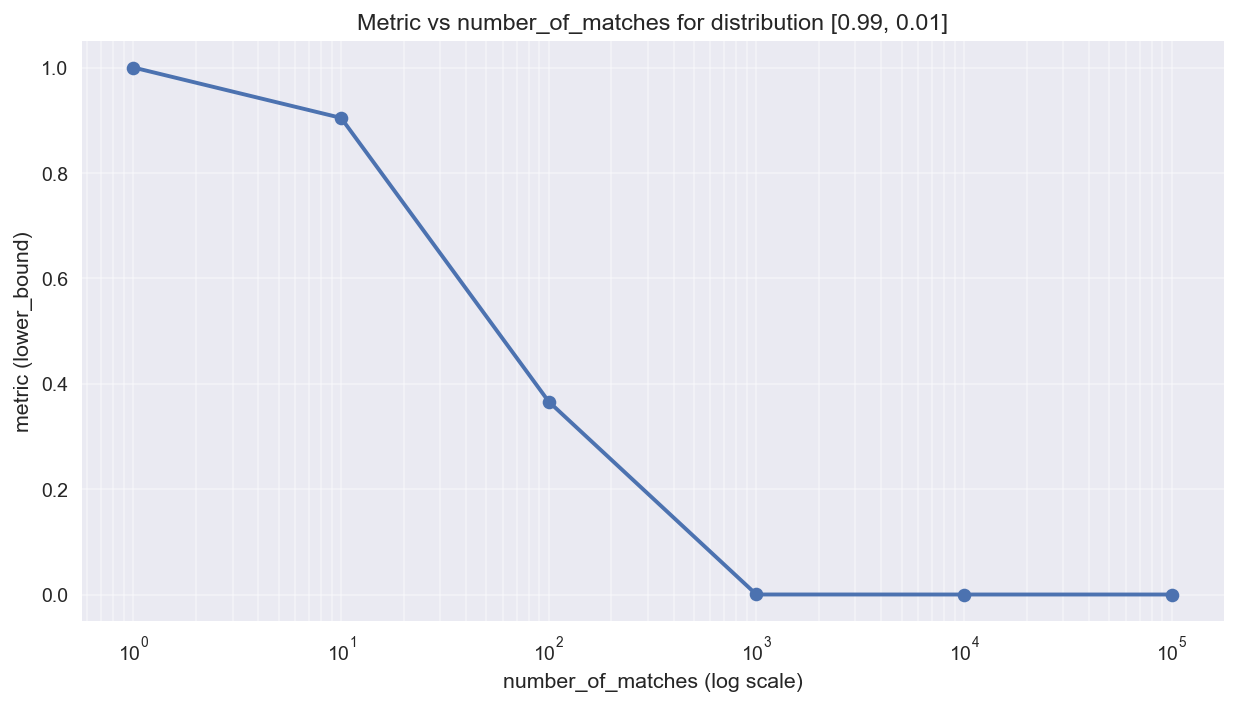

In [97]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import logsumexp

def lower_bound(max_matches, p_rhs):
    p_rhs = np.asarray(p_rhs, dtype=float)
    return float(np.exp(logsumexp(max_matches * np.log(p_rhs))))

# ---- Plot 1: fixed matches, varying p ----
n_matches = 10
ps = np.round(np.arange(1.00, 0.49, -0.001), 2)  # 1.00 down to 0.50 inclusive
vals1 = np.array([lower_bound(n_matches, [p, 1 - p]) for p in ps])

plt.style.use("seaborn-v0_8")
fig1, ax1 = plt.subplots(figsize=(9, 5.2), dpi=140)
ax1.plot(ps, vals1, linewidth=2)
ax1.set_title("Metric vs p for distribution [p, 1-p] (number_of_matches=10)")
ax1.set_xlabel("p")
ax1.set_ylabel("metric (lower_bound)")
ax1.set_xlim(1.0, 0.5)
ax1.grid(True, which="both", alpha=0.35)
plt.tight_layout()
plt.show()

# ---- Plot 1: fixed matches, varying p ----

n_matches = 1000
ps = np.round(np.arange(1.00, 0.98, -0.0001), 5)  # 1.00 down to 0.50 inclusive
vals1 = np.array([lower_bound(n_matches, [p, 1 - p]) for p in ps])

plt.style.use("seaborn-v0_8")
fig1, ax1 = plt.subplots(figsize=(9, 5.2), dpi=140)
ax1.plot(ps, vals1, linewidth=2)
ax1.set_title("Metric vs p for distribution [p, 1-p] (number_of_matches=1000)")
ax1.set_xlabel("p")
ax1.set_ylabel("metric (lower_bound)")
ax1.set_xlim(1.0, 0.98)
ax1.grid(True, which="both", alpha=0.35)
plt.tight_layout()
plt.show()

# ---- Plot 2: fixed p, varying matches ----
p_fixed = [0.99, 0.01]
ks = np.arange(0, 6)
matches = (10 ** ks).astype(int)
vals2 = np.array([lower_bound(m, p_fixed) for m in matches])

fig2, ax2 = plt.subplots(figsize=(9, 5.2), dpi=140)
ax2.plot(matches, vals2, marker="o", linewidth=2)
ax2.set_xscale("log")
ax2.set_title("Metric vs number_of_matches for distribution [0.99, 0.01]")
ax2.set_xlabel("number_of_matches (log scale)")
ax2.set_ylabel("metric (lower_bound)")
ax2.grid(True, which="both", alpha=0.35)
plt.tight_layout()
plt.show()


In [132]:
from scipy.special import logsumexp
def lower_bound_log(max_matches, p_rhs):
    return logsumexp( max_matches * np.log(p_rhs))

In [ ]:
def improved_lower_bound(k_matches, p_rhs):
    K = np.float64(len(k_matches))
    result = 0.0
    for m in k_matches:
        result += lower_bound_log(m, p_rhs)
    return np.exp(result)

In [143]:
improved_lower_bound([100,900, 2, 2, 2, 2, 2], [0.2,0.8])

np.float64(1.7886754880552818e-98)

In [144]:
improved_lower_bound([1,9], [0.2,0.8])

np.float64(0.13421824000000004)

In [147]:
test = [
    [10, [1,9], [0.1, 0.9]],
    [10, [1,9], [0.001, 0.999]],
    [10, [5,5], [0.1, 0.9]],
    [10, [5,5], [0.001, 0.999]],
    [1000, [100,900], [0.1, 0.9]],
    [1000, [100,900], [0.001, 0.999]],
    [1000, [1,999], [0.001, 0.999]],
    [1000, [1,999], [0.2,0.2, 0.6]],
]
for n,ks, p_rhs in test:
    print(f'{n} samples with {ks} class dist. and {p_rhs} dist: {improved_lower_bound(ks, p_rhs)}')

10 samples with [1, 9] class dist. and [0.1, 0.9] dist: 0.38742049000000006
10 samples with [1, 9] class dist. and [0.001, 0.999] dist: 0.991035916125874
10 samples with [5, 5] class dist. and [0.1, 0.9] dist: 0.34869025000000003
10 samples with [5, 5] class dist. and [0.001, 0.999] dist: 0.9900448802097502
1000 samples with [100, 900] class dist. and [0.1, 0.9] dist: 1.7478712517226825e-46
1000 samples with [100, 900] class dist. and [0.001, 0.999] dist: 0.36769542477096373
1000 samples with [1, 999] class dist. and [0.001, 0.999] dist: 0.36806348825922297
1000 samples with [1, 999] class dist. and [0.2, 0.2, 0.6] dist: 2.3610171039723854e-222


In [148]:
lower_bound_log(1,[0.5,0.5])

np.float64(0.0)